# 13 - Text Classification: TF-IDF vs Sentence Embeddings vs Fine-tuned DistilBERT
**Topic:** NLP  |  **Reference:** "Building a Text Classification Pipeline with Hugging Face Transformers" (amanxai.com, Jul 2025)

**Question.** Which of 20 newsgroup topics does a post belong to, and how much does a transformer really add over a classic bag-of-words model?

**Reference method:** the 20 Newsgroups data (headers, footers and quotes removed), a **random 80/20 split** of all 18,846 posts, DistilBERT fine-tuned with the Hugging Face `Trainer`.
**What I add:** (1) the **same data three ways** to measure how much the evaluation setup (random vs the official date-based split; headers removed or not) changes the score; (2) strong classic baselines (TF-IDF + linear models) and sentence embeddings, so the transformer must *earn* its cost; (3) a DistilBERT fine-tune that fits on a CPU (shorter inputs, a subset of the training data), compared fairly against a classic model trained on the **same** subset; (4) which topics are confused and why.

## 1. Libraries and data

In [1]:
import warnings, os, json, joblib, time, re
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import torch, torch.nn.functional as F
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
sns.set_theme(style="whitegrid", context="notebook")
torch.manual_seed(0); np.random.seed(0); torch.set_num_threads(6)
os.makedirs("model", exist_ok=True)
RM = ("headers", "footers", "quotes")
tr = fetch_20newsgroups(subset="train", remove=RM); te = fetch_20newsgroups(subset="test", remove=RM)
tr_raw = fetch_20newsgroups(subset="train"); te_raw = fetch_20newsgroups(subset="test")
names = tr.target_names; ytr, yte = tr.target, te.target
print(len(tr.data), "train |", len(te.data), "test (official split is by date: test posts are later than train posts) |", len(names), "topics")

11314 train | 7532 test (official split is by date: test posts are later than train posts) | 20 topics


## 2. Look at the data first

words per post: median 83, 90th pct 336, max 11765 | empty posts after cleaning: 300 (2.7%)


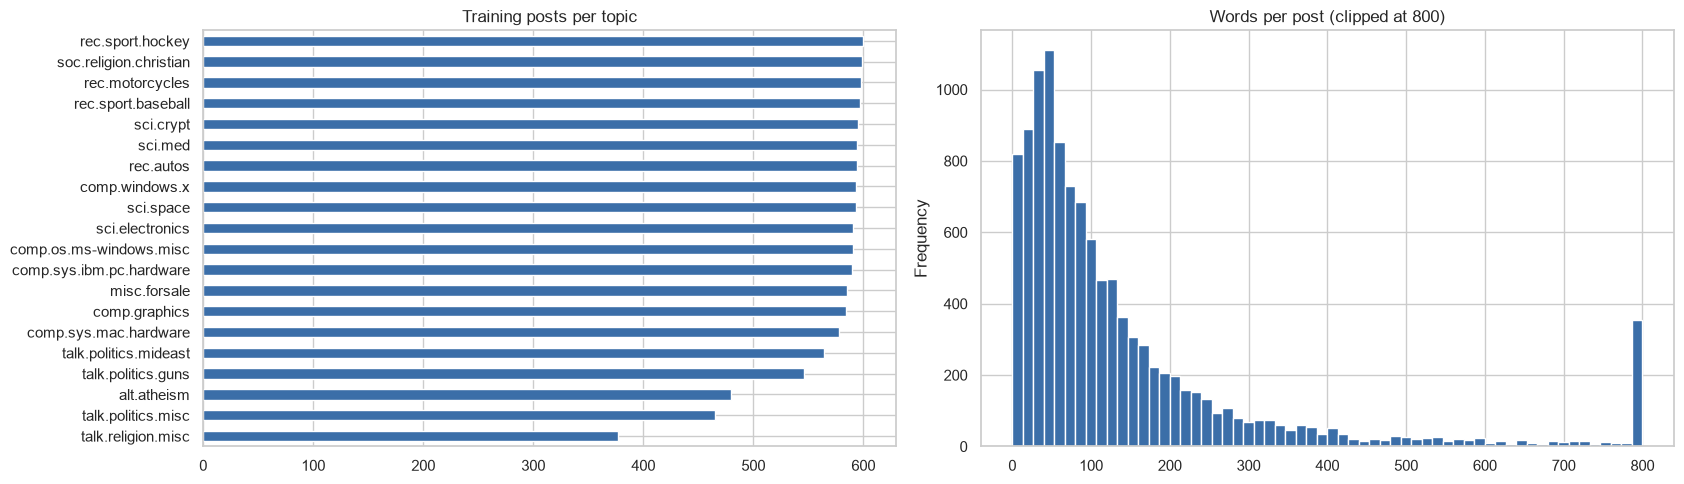

example (cleaned, first 300 characters): '\n\n\n\n\nOf course.  The term must be rigidly defined in any bill.\n\n\nI doubt she uses this term for that.  You are using a quote allegedly\nfrom her, can you back it up?\n\n\n\n\nI read the article as presenting first an argument about weapons of mass\ndestruction (as commonly understood) and then switching to'
same post with headers kept (first 300 characters): 'From: dfo@vttoulu.tko.vtt.fi (Foxvog Douglas)\nSubject: Re: Rewording the Second Amendment (ideas)\nOrganization: VTT\nLines: 58\n\nIn article <1r1eu1$4t@transfer.stratus.com> cdt@sw.stratus.com (C. D. Tavares) writes:\n>In article <1993Apr20.083057.16899@ousrvr.oulu.fi>, dfo@vttoulu.tko.vtt.fi (Foxvog Do'


In [2]:
lens = pd.Series([len(t.split()) for t in tr.data])
print("words per post: median %d, 90th pct %d, max %d | empty posts after cleaning: %d (%.1f%%)" % (lens.median(), lens.quantile(.9), lens.max(), (lens == 0).sum(), (lens == 0).mean() * 100))
fig, ax = plt.subplots(1, 2, figsize=(17, 5))
pd.Series(ytr).map(dict(enumerate(names))).value_counts().sort_values().plot.barh(ax=ax[0], color="#3b6ea8"); ax[0].set_title("Training posts per topic")
lens.clip(upper=800).plot.hist(bins=60, ax=ax[1], color="#3b6ea8"); ax[1].set_title("Words per post (clipped at 800)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()
print("example (cleaned, first 300 characters):", repr(tr.data[5][:300])); print("same post with headers kept (first 300 characters):", repr(tr_raw.data[5][:300]))

**Reading it.** 11,314 training and 7,532 test posts over 20 topics; the official split is **by date** (the test posts were written after the training posts). Posts are short and very uneven: median 83 words, 90th percentile 336, longest 11,765. After removing headers, footers and quoted text **300 posts (2.7%) are empty** and cannot be classified from their content. The second example shows what the removal takes away: the kept version begins with the sender's address, subject and organisation, which can identify the topic without the text being read.

## 3. Does the evaluation setup matter? One model, five set-ups
TF-IDF (1-2 word n-grams) + logistic regression everywhere; only the data handling changes.

In [3]:
def run(Xa, ya, Xb, yb, C=10):
    v = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_features=300000, stop_words="english"); A = v.fit_transform(Xa); B = v.transform(Xb)
    m = LogisticRegression(C=C, max_iter=300).fit(A, ya); return accuracy_score(yb, m.predict(B))
allX = tr.data + te.data; ally = np.r_[ytr, yte]
a1 = run(tr.data, ytr, te.data, yte)
Xa, Xb, ya, yb = train_test_split(allX, ally, test_size=.2, random_state=42); a2 = run(Xa, ya, Xb, yb)
a3 = run(tr_raw.data, ytr, te_raw.data, yte)
Xr = tr_raw.data + te_raw.data; Xa, Xb, ya, yb = train_test_split(Xr, ally, test_size=.2, random_state=42); a4 = run(Xa, ya, Xb, yb)
setup = pd.DataFrame({"accuracy_%": [a1 * 100, a2 * 100, a3 * 100, a4 * 100]}, index=["official split (by date), headers/footers/quotes removed", "RANDOM 80/20 split (the reference's), removed",
                      "official split, headers/footers/quotes KEPT", "random 80/20 split, KEPT"]); print(setup.round(1).to_string())

                                                          accuracy_%
official split (by date), headers/footers/quotes removed        70.3
RANDOM 80/20 split (the reference's), removed                   75.8
official split, headers/footers/quotes KEPT                     85.7
random 80/20 split, KEPT                                        93.3


**Reading it (same TF-IDF + logistic regression, only the data handling changes).**

| set-up | accuracy |
|---|---|
| official split (by date), headers/footers/quotes removed | **70.3%** |
| random 80/20 split of all posts (the reference's set-up), removed | 75.8% |
| official split, headers/footers/quotes **kept** | 85.7% |
| random 80/20 split, kept | 93.3% |

The same model scores anywhere from 70% to 93% depending on how it is evaluated. A random split lets the model see earlier and later posts of the same threads and the same authors (+5.5 points); leaving the headers in lets it read the sender, organisation and subject line (+15.4 points on the official split). I use the first row, the hardest and most honest one, for everything that follows, so **the headline numbers of this notebook are not comparable with scores quoted for the random-split set-up**.

**For all following models** I use the *official date-based split with headers, footers and quotes removed*: it is the hardest and the most honest of the four, since the test posts come after the training posts and the metadata shortcuts are gone.

## 4. Classic baselines
Majority class, TF-IDF + logistic regression, TF-IDF + linear SVM. Also trained on a **6,000-post subset** (the same subset the DistilBERT model will see) to compare fairly.

In [4]:
vec = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_features=300000, stop_words="english")
Atr = vec.fit_transform(tr.data); Ate = vec.transform(te.data)
t = time.time(); lr = LogisticRegression(C=10, max_iter=300).fit(Atr, ytr); t_lr = time.time() - t
t = time.time(); svm = LinearSVC(C=0.5).fit(Atr, ytr); t_svm = time.time() - t
P = {"TF-IDF + logistic regression": lr.predict(Ate), "TF-IDF + linear SVM": svm.predict(Ate)}
rs = np.random.RandomState(0); sub = rs.choice(len(tr.data), 6000, replace=False)
vs = TfidfVectorizer(sublinear_tf=True, ngram_range=(1, 2), min_df=2, max_features=300000, stop_words="english"); As = vs.fit_transform([tr.data[i] for i in sub]); lrs = LogisticRegression(C=10, max_iter=300).fit(As, ytr[sub])
P["TF-IDF + LR, 6,000-post subset"] = lrs.predict(vs.transform(te.data))
print("majority class accuracy: %.1f%%" % (np.bincount(yte).max() / len(yte) * 100))
for k, p in P.items(): print("%-34s accuracy %.1f%% | macro-F1 %.3f" % (k, accuracy_score(yte, p) * 100, f1_score(yte, p, average="macro")))
print("fit time: LR %.0fs, SVM %.0fs" % (t_lr, t_svm))

majority class accuracy: 5.3%
TF-IDF + logistic regression       accuracy 70.3% | macro-F1 0.692
TF-IDF + linear SVM                accuracy 70.6% | macro-F1 0.694
TF-IDF + LR, 6,000-post subset     accuracy 67.6% | macro-F1 0.663
fit time: LR 57s, SVM 2s


## 5. Sentence embeddings + logistic regression
`all-MiniLM-L6-v2` (22 million parameters, a general-purpose sentence model, **not** fine-tuned) turns each post into a 384-number vector (inputs cut at 256 tokens); a logistic regression is trained on top. Cached after the first run.

In [5]:
from sentence_transformers import SentenceTransformer
cache = "../_data/20ng_minilm.npz"
st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2"); st.max_seq_length = 256
if os.path.exists(cache): z = np.load(cache); Etr, Ete = z["tr"], z["te"]
else:
    t = time.time(); Etr = st.encode(tr.data, batch_size=64, normalize_embeddings=True); Ete = st.encode(te.data, batch_size=64, normalize_embeddings=True); np.savez_compressed(cache, tr=Etr, te=Ete); print("encoding time %.0fs" % (time.time() - t))
lre = LogisticRegression(C=20, max_iter=1000).fit(Etr, ytr); P["MiniLM embeddings + LR"] = lre.predict(Ete)
print("MiniLM embeddings + logistic regression: accuracy %.1f%%, macro-F1 %.3f" % (accuracy_score(yte, P["MiniLM embeddings + LR"]) * 100, f1_score(yte, P["MiniLM embeddings + LR"], average="macro")))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

MiniLM embeddings + logistic regression: accuracy 65.4%, macro-F1 0.643


## 6. Fine-tuning DistilBERT on a CPU
`distilbert-base-uncased` (66 million parameters), classification head on top, trained end-to-end. To fit a CPU: the same 6,000-post subset as above, inputs cut at **128 tokens** (the reference uses 512), batch 16, 2 epochs, AdamW with a linear warm-up/decay schedule. It is evaluated on the full 7,532-post test set.

In [6]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
tok = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased")
model = AutoModelForSequenceClassification.from_pretrained("distilbert/distilbert-base-uncased", num_labels=20)
enc = lambda txt: tok(txt, truncation=True, max_length=128, padding=True, return_tensors="pt")
sub_texts = [tr.data[i] for i in sub]; sub_y = torch.from_numpy(ytr[sub])
EPOCHS, BS = 2, 16; steps = EPOCHS * (len(sub) // BS)
opt = torch.optim.AdamW(model.parameters(), lr=5e-5, weight_decay=0.01); sch = get_linear_schedule_with_warmup(opt, int(.06 * steps), steps)
t0 = time.time(); step = 0
for ep in range(EPOCHS):
    model.train(); perm = np.random.RandomState(ep).permutation(len(sub)); run_loss = []
    for k in range(0, len(perm) - BS + 1, BS):
        idx = perm[k:k + BS]; b = enc([sub_texts[i] for i in idx]); out = model(**b, labels=sub_y[idx]); out.loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step(); sch.step(); opt.zero_grad(); run_loss.append(out.loss.item()); step += 1
    print(f"  epoch {ep+1}: mean training loss {np.mean(run_loss):.3f} (elapsed {time.time()-t0:.0f}s)")
t_train = time.time() - t0

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  epoch 1: mean training loss 1.686 (elapsed 2347s)


  epoch 2: mean training loss 0.849 (elapsed 7488s)


In [7]:
model.eval(); probs = []; t0 = time.time()
with torch.no_grad():
    for k in range(0, len(te.data), 64): probs.append(F.softmax(model(**enc(te.data[k:k + 64])).logits, 1))
probs = torch.cat(probs).numpy(); P["DistilBERT fine-tuned (6,000 posts, 128 tokens)"] = probs.argmax(1); t_pred = time.time() - t0
print("DistilBERT: accuracy %.1f%%, macro-F1 %.3f | train %.0fs, predict 7,532 posts %.0fs" % (accuracy_score(yte, probs.argmax(1)) * 100, f1_score(yte, probs.argmax(1), average="macro"), t_train, t_pred))

DistilBERT: accuracy 66.7%, macro-F1 0.644 | train 7488s, predict 7,532 posts 787s


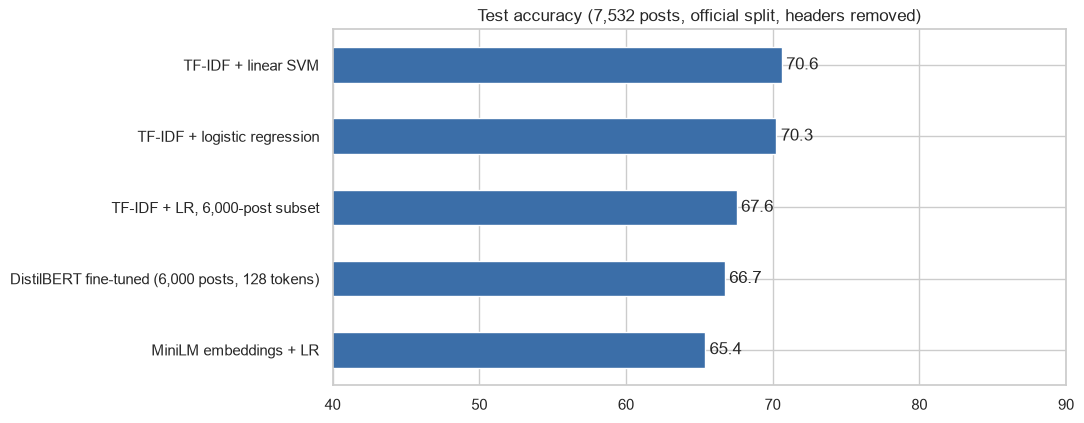

                                                 accuracy_%  macro_F1
MiniLM embeddings + LR                               65.401     0.643
DistilBERT fine-tuned (6,000 posts, 128 tokens)      66.742     0.644
TF-IDF + LR, 6,000-post subset                       67.552     0.663
TF-IDF + logistic regression                         70.260     0.692
TF-IDF + linear SVM                                  70.619     0.694


In [8]:
res = pd.DataFrame({"accuracy_%": {k: accuracy_score(yte, p) * 100 for k, p in P.items()}, "macro_F1": {k: f1_score(yte, p, average="macro") for k, p in P.items()}}).sort_values("accuracy_%")
ax = res["accuracy_%"].plot.barh(figsize=(11, 4.4), color="#3b6ea8"); ax.set_xlim(40, 90); ax.set_title("Test accuracy (7,532 posts, official split, headers removed)")
for i, v in enumerate(res["accuracy_%"]): ax.text(v + .3, i, f"{v:.1f}", va="center")
plt.tight_layout(); plt.show(); print(res.round(3).to_string())

**Reading it (7,532 test posts; a sampling interval of roughly +/-1 point for each accuracy, wider for differences between models that were not tested pairwise).**

| model | accuracy | macro-F1 |
|---|---|---|
| majority class | 5.3% | - |
| MiniLM embeddings + logistic regression | 65.4% | 0.643 |
| DistilBERT fine-tuned (6,000 posts, 128 tokens, 2 epochs) | 66.7% | 0.644 |
| TF-IDF + logistic regression, 6,000-post subset | 67.6% | 0.663 |
| TF-IDF + logistic regression (all 11,314 posts) | 70.3% | 0.692 |
| TF-IDF + linear SVM | 70.6% | 0.694 |

* **The classic bag-of-words model is the best here**, and the linear SVM and logistic regression differ by 0.3 points, which is noise. They fit in 57 s and 2 s on a CPU.
* **The fine-tuned DistilBERT did not beat TF-IDF.** Against the TF-IDF model trained on the *same* 6,000 posts, it is 0.9 points lower (66.7% vs 67.6%), a difference I would not call real with one run; against the full-data TF-IDF it is 3.6 points lower. It needed 7,488 s (about 2 hours) of CPU training, and 787 s to classify 7,532 posts.
* **This is not a verdict on transformers.** To fit a CPU I gave DistilBERT only 6,000 posts, cut inputs at 128 tokens (the median post has 83 words, but 10% have over 336) and trained for 2 epochs with no tuning, one seed; the reference's set-up (all posts, 512 tokens) was not run. What this shows is that a pretrained transformer is **not** automatically better than TF-IDF when data, text length and compute are limited, and that the evaluation set-up (row above) moves the score far more than the model choice does.
* MiniLM embeddings without fine-tuning are 5 points behind TF-IDF: sentence embeddings capture general meaning, while newsgroup topics are often decided by particular words (`scsi`, `nhl`, `toyota`).

## 7. Which topics are confused?

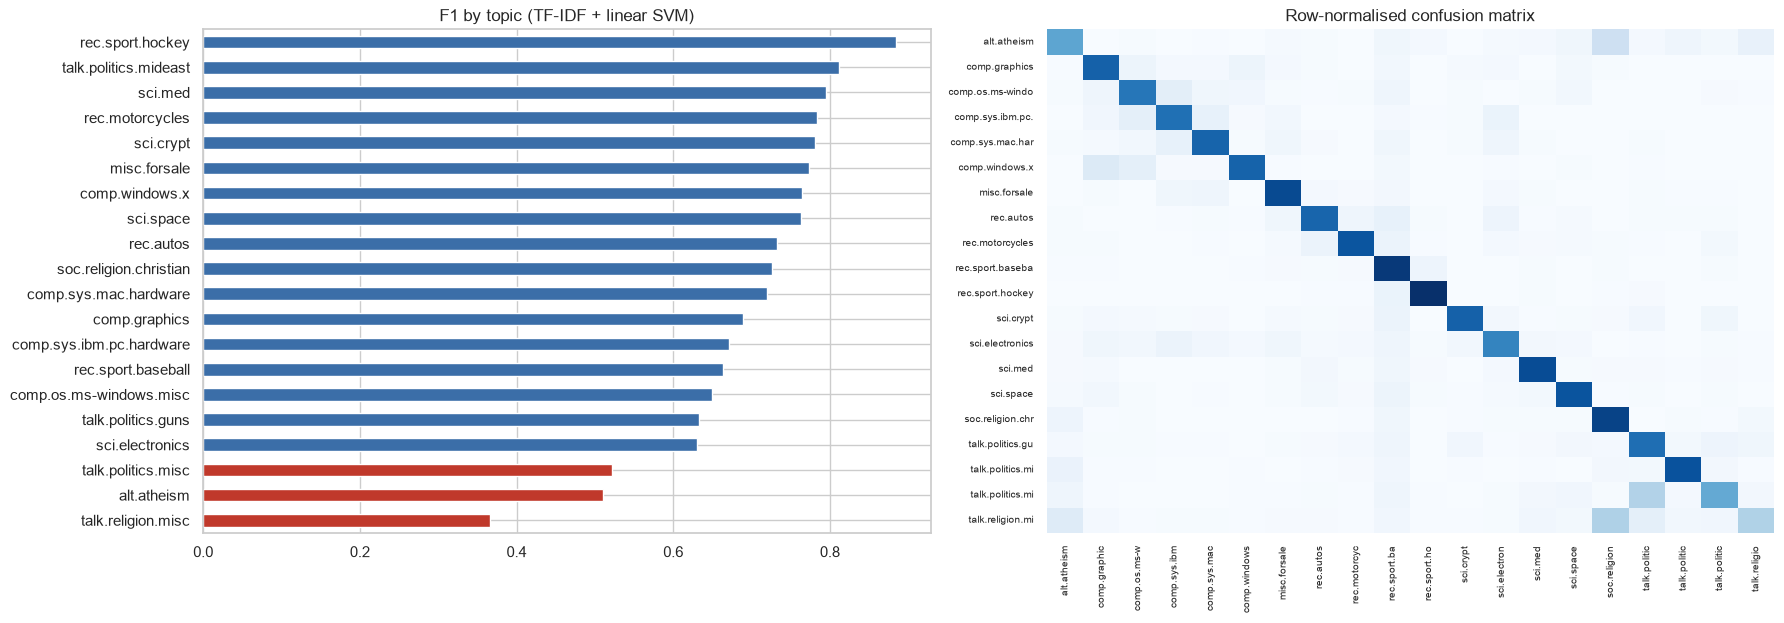

best model: TF-IDF + linear SVM
top confusions (true -> predicted: count): ['talk.politics.misc -> talk.politics.guns: 87', 'talk.religion.misc -> soc.religion.christian: 72', 'alt.atheism -> soc.religion.christian: 59', 'comp.windows.x -> comp.graphics: 47', 'comp.os.ms-windows.misc -> comp.sys.ibm.pc.hardware: 36', 'comp.windows.x -> comp.os.ms-windows.misc: 34']
lowest F1: {'talk.religion.misc': 0.37, 'alt.atheism': 0.51, 'talk.politics.misc': 0.52, 'sci.electronics': 0.63}


In [9]:
best = max(P, key=lambda k: accuracy_score(yte, P[k])); pb = P[best]
cm = confusion_matrix(yte, pb); off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], names[i], names[j]) for i in range(20) for j in range(20)], reverse=True)[:6]
f1 = pd.Series(f1_score(yte, pb, average=None), index=names).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(18, 6.4))
f1.plot.barh(ax=ax[0], color=["#c0392b" if v < .6 else "#3b6ea8" for v in f1]); ax[0].set_title(f"F1 by topic ({best})")
sns.heatmap(cm / cm.sum(1, keepdims=True), cmap="Blues", ax=ax[1], cbar=False, xticklabels=[n[:12] for n in names], yticklabels=[n[:16] for n in names]); ax[1].set_title("Row-normalised confusion matrix"); ax[1].tick_params(labelsize=7)
plt.tight_layout(); plt.show()
print("best model:", best); print("top confusions (true -> predicted: count):", [f"{a} -> {b}: {c}" for c, a, b in pairs]); print("lowest F1:", f1.head(4).round(2).to_dict())

**Reading it (best model, TF-IDF + linear SVM).** Sports, medicine and motorcycles are easy (F1 0.8 and above, e.g. `rec.sport.hockey` highest); the weakest are `talk.religion.misc` (F1 0.37), `alt.atheism` (0.51) and `talk.politics.misc` (0.52). The confusions are between topics that genuinely overlap: `talk.politics.misc` is taken for `talk.politics.guns` (87 posts), `talk.religion.misc` for `soc.religion.christian` (72), `alt.atheism` for `soc.religion.christian` (59), `comp.windows.x` for `comp.graphics` (47). Many of these are "miscellaneous" groups, which by definition have no sharp topic, so some of this error is the labelling rather than the model.

## 8. What does the linear model look at? Top words per topic (logistic regression coefficients)

In [10]:
fn = np.array(vec.get_feature_names_out()); show = [0, 3, 7, 10, 15, 17]
for c in show: print(f"{names[c]:28s}", ", ".join(fn[np.argsort(-lr.coef_[c])[:10]]))

alt.atheism                  religion, atheism, atheists, islam, islamic, motto, god, deletion, bible, bobby
comp.sys.ibm.pc.hardware     pc, card, monitor, controller, ide, scsi, vlb, bus, drive, bios
rec.autos                    car, cars, oil, dealer, ford, toyota, engine, vw, gt, honda
rec.sport.hockey             hockey, team, game, nhl, season, play, games, mask, players, leafs
soc.religion.christian       god, church, christians, jesus, christ, christian, christianity, bible, faith, marriage
talk.politics.mideast        israel, israeli, arab, jews, turkish, armenians, loser, arabs, turkey, jewish


**Reading it.** For most topics the largest weights are the words one would expect (`scsi`, `ide`, `bios` for PC hardware; `hockey`, `nhl`, `leafs`; `car`, `toyota`, `dealer`). A few are not topic words: `motto`, `deletion` and `bobby` for `alt.atheism`, `loser` for `talk.politics.mideast`. Those look like quirks of a few frequent posters (signature lines, favourite insults) that survive the header removal; the model has learned them as if they were topic evidence, and they would not carry over to other text. The model is a bag of words weights, not an understanding of the topic, and weights show association in this training set, not what a topic is about.

## 9. Save

In [11]:
joblib.dump({"vectorizer": vec, "clf": lr, "names": names}, "model/tfidf_logreg.joblib")
joblib.dump({"clf": lre, "names": names, "embedder": "sentence-transformers/all-MiniLM-L6-v2", "max_seq_length": 256}, "model/minilm_logreg.joblib")
model.save_pretrained("model/distilbert_20ng"); tok.save_pretrained("model/distilbert_20ng")
json.dump({"setup": setup["accuracy_%"].round(1).to_dict(), "test": res.round(3).to_dict("index"), "train_seconds_distilbert": round(t_train), "predict_seconds_distilbert_7532": round(t_pred)}, open("model/meta.json", "w"), indent=1)
print(os.listdir("model"))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

['distilbert_20ng', 'meta.json', 'minilm_logreg.joblib', 'tfidf_logreg.joblib']


## 10. Summary: my approach vs the reference
| | Reference | This notebook |
|---|---|---|
| Split | random 80/20 over all 18,846 posts | official date-based split (7,532 later posts as the test set) |
| Evaluation set-up | one | four set-ups: 70.3% (honest) to 93.3% (random split with headers kept) for the same model |
| Models | DistilBERT fine-tuned (full data, 512 tokens) | TF-IDF LR 70.3%, TF-IDF SVM 70.6%, MiniLM + LR 65.4%, **DistilBERT on a CPU budget 66.7%** (6,000 posts, 128 tokens) |
| Fair comparison | none | TF-IDF trained on the same 6,000 posts: 67.6%; majority class 5.3% |
| Errors | not examined | overlapping "misc"/religion/politics groups; quirk words learned as topic evidence |

**What I learned.** (1) The way a text set is split and cleaned changes the headline score (70% to 93% for one model) by more than the choice of model does; always state the set-up. (2) A fine-tuned transformer is not automatically better than TF-IDF + a linear model: with 6,000 examples, 128 tokens and 2 CPU hours it was not. (3) Always include the simple baseline trained on the *same* data. (4) Look at the largest weights of a linear model: they reveal shortcuts.

**Limits.** My DistilBERT run is a reduced budget (about 53% of the training posts, 128 tokens, 2 epochs, one seed, no tuning), so it says nothing about the full-data, 512-token transformer used by the reference. No confidence intervals were computed for the model differences. 20 Newsgroups is old, informal English from 1993; the date-based split is stricter than a random one, but the same authors and threads can still appear in both parts. **Next step:** run the full-data/512-token fine-tune on a GPU, add a paired test between the best TF-IDF and the transformer, and check with a split by author or thread.